In [1]:
pip install xgboost

Note: you may need to restart the kernel to use updated packages.


Import

In [1]:
from xgboost import XGBClassifier

Load Dataset

In [2]:
import pandas as pd

df = pd.read_csv("bihar_flood_data.csv")  # change path

Handle Date Column

In [3]:
if 'Date' in df.columns:
    df['Date'] = pd.to_datetime(df['Date'])
    
    df['year'] = df['Date'].dt.year
    df['month'] = df['Date'].dt.month
    df['day'] = df['Date'].dt.day
    
    df = df.drop(columns=['Date'])

Encode Categorical Data

In [4]:
df = pd.get_dummies(df, drop_first=True)

Define Features & Target

In [5]:
target_column = "Flood"   # change if needed

X = df.drop(columns=[target_column])
y = df[target_column]

Train-Test Split

In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

Scaling

In [7]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

Import XGBoost

In [8]:
from xgboost import XGBClassifier

Train XGBoost

In [9]:
xgb_model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=5,
    random_state=42,
    use_label_encoder=False,
    eval_metric='logloss'
)

xgb_model.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.1, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=5,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=100,
              n_jobs=None, num_parallel_tree=None, random_state=42, ...)

Predictions

In [10]:
y_pred_xgb = xgb_model.predict(X_test)

Evaluation

In [11]:
from sklearn.metrics import accuracy_score, f1_score, classification_report

accuracy_xgb = accuracy_score(y_test, y_pred_xgb)
f1_xgb = f1_score(y_test, y_pred_xgb)

print("XGB Accuracy:", accuracy_xgb)
print("XGB F1 Score:", f1_xgb)

print(classification_report(y_test, y_pred_xgb))

XGB Accuracy: 0.9410714285714286
XGB F1 Score: 0.8235294117647058
              precision    recall  f1-score   support

           0       0.95      0.98      0.96       921
           1       0.88      0.77      0.82       199

    accuracy                           0.94      1120
   macro avg       0.92      0.88      0.89      1120
weighted avg       0.94      0.94      0.94      1120



DETAILED REPORT

In [12]:
from sklearn.metrics import classification_report

print("=== Classification Report (XGBoost) ===")
print(classification_report(y_test, y_pred_xgb))

=== Classification Report (XGBoost) ===
              precision    recall  f1-score   support

           0       0.95      0.98      0.96       921
           1       0.88      0.77      0.82       199

    accuracy                           0.94      1120
   macro avg       0.92      0.88      0.89      1120
weighted avg       0.94      0.94      0.94      1120



CONFUSION MATRIX

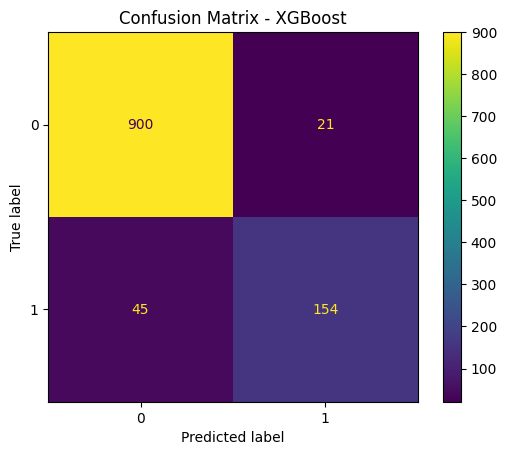

In [13]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_estimator(xgb_model, X_test, y_test)
plt.title("Confusion Matrix - XGBoost")
plt.show()

FEATURE IMPORTANCE

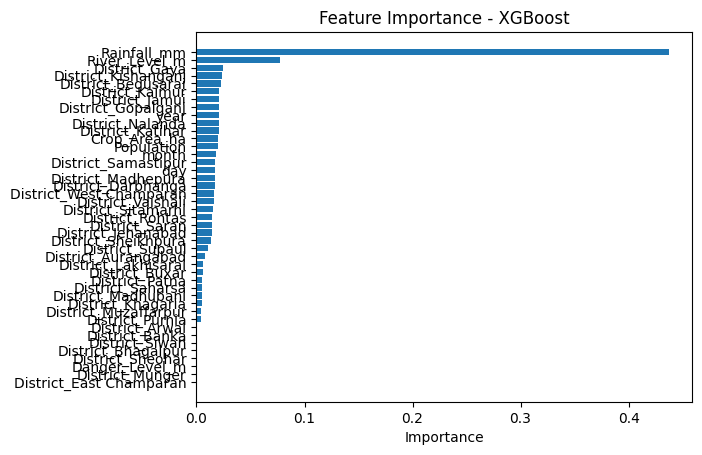

In [14]:
import numpy as np

importances = xgb_model.feature_importances_

# If you used scaling → recover column names from original X
feature_names = X.columns

indices = np.argsort(importances)

plt.figure()
plt.barh(range(len(indices)), importances[indices])
plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
plt.xlabel("Importance")
plt.title("Feature Importance - XGBoost")
plt.show()

ROC CURVE

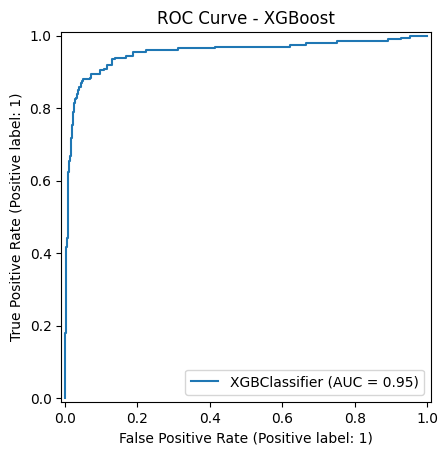

In [15]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_estimator(xgb_model, X_test, y_test)
plt.title("ROC Curve - XGBoost")
plt.show()

PRECISION-RECALL CURVE

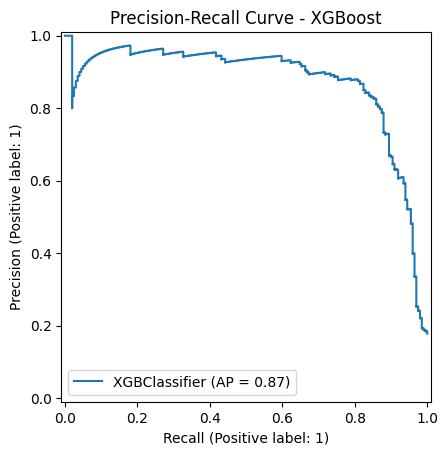

In [16]:
from sklearn.metrics import PrecisionRecallDisplay

PrecisionRecallDisplay.from_estimator(xgb_model, X_test, y_test)
plt.title("Precision-Recall Curve - XGBoost")
plt.show()

PREDICTION DISTRIBUTION

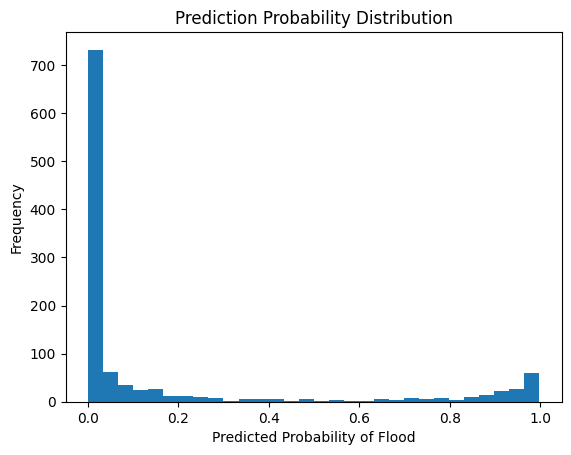

In [17]:
y_prob = xgb_model.predict_proba(X_test)[:,1]

plt.figure()
plt.hist(y_prob, bins=30)
plt.title("Prediction Probability Distribution")
plt.xlabel("Predicted Probability of Flood")
plt.ylabel("Frequency")
plt.show()

In [18]:
import joblib

# Save model
joblib.dump(xgb_model, "xgb_model.pkl")

# Save scaler (VERY IMPORTANT)
joblib.dump(scaler, "xgb_scaler.pkl")

print("Model saved successfully!")

Model saved successfully!
